# SPY Hourly Direction Model: Complete Experiment

This notebook reconstructs the full research path that produced a **43.30% net return** on the held-out test period. It includes data acquisition, data reading and validation, feature engineering, baseline models, exhaustive feature selection, the validation-selected model, the all-feature model, and a fair strategy comparison.

The experiment is pinned to **2016-06-28 through 2026-07-10**. The final result is an historical backtest result, not a forecast of future performance.

## 1. Setup and reproducible configuration

This notebook has no project-specific imports and can run from an otherwise empty directory. It creates its own `data/` folders, reuses a compatible local cache when present, and otherwise downloads the pinned Alpaca snapshot. A fresh download requires `APCA_API_KEY_ID` and `APCA_API_SECRET_KEY` in the environment. Required packages are listed below; install any missing packages in the notebook environment with `%pip install alpaca-py polars pyarrow numpy pandas scikit-learn matplotlib`.

In [3]:
from datetime import date, datetime, time
from pathlib import Path
import hashlib
import itertools
import json
import os
import sqlite3
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    mean_squared_error,
    r2_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

SYMBOL = 'SPY'
START_DATE = date(2016, 6, 28)
END_DATE = date(2026, 7, 10)
TRADING_HOURS_IN_DAY = 8
TRANSACTION_COST_BPS = 1.0
DOWNLOAD_IF_MISSING = True

STARTING_DIR = Path.cwd()
WORK_DIR = next(
    (candidate for candidate in [STARTING_DIR, *STARTING_DIR.parents]
     if (candidate / 'data' / 'raw' / SYMBOL).is_dir()),
    STARTING_DIR,
)
DATA_DIR = WORK_DIR / 'data'
RAW_DATA_PATH = DATA_DIR / 'raw' / SYMBOL
SNAPSHOT_PATH = RAW_DATA_PATH / f'{SYMBOL}-bars-1h-{START_DATE}_{END_DATE}.parquet'
PROCESSED_DATA_PATH = (
    DATA_DIR / 'processed'
    / f'spy_hourly_feature_target_data_{START_DATE}_{END_DATE}.parquet'
)
SEARCH_DB_PATH = DATA_DIR / 'processed' / 'logistic_feature_search.sqlite'

print(f'Working directory: {WORK_DIR}')
print(f'Pinned window: {START_DATE} through {END_DATE}')
print(f'Download missing data: {DOWNLOAD_IF_MISSING}')

Working directory: /home/deva/Documents/CS 363M/project
Pinned window: 2016-06-28 through 2026-07-10
Download missing data: True


## 2. Download the pinned Alpaca data

Alpaca supplies hourly SIP bars. On a fresh run, the notebook downloads the complete pinned window and writes one local parquet snapshot. The Alpaca import is kept inside the download function, so rerunning from an existing cache does not require `alpaca-py`.

In [4]:
def alpaca_credentials():
    api_key = os.getenv('APCA_API_KEY_ID')
    secret_key = os.getenv('APCA_API_SECRET_KEY')
    if not api_key or not secret_key:
        raise RuntimeError(
            'No compatible local data cache was found. Set APCA_API_KEY_ID and '
            'APCA_API_SECRET_KEY, then rerun this cell to download the pinned data.'
        )
    return api_key, secret_key

def download_pinned_snapshot(output_path):
    try:
        from alpaca.data.enums import DataFeed
        from alpaca.data.historical import StockHistoricalDataClient
        from alpaca.data.requests import StockBarsRequest
        from alpaca.data.timeframe import TimeFrame
    except ModuleNotFoundError as exc:
        raise RuntimeError(
            'alpaca-py is required for a fresh download. Run `%pip install alpaca-py` '
            'and restart the kernel.'
        ) from exc

    api_key, secret_key = alpaca_credentials()
    eastern = ZoneInfo('America/New_York')
    utc = ZoneInfo('UTC')
    request_start = datetime.combine(START_DATE, time(9, 30), eastern).astimezone(utc)
    request_end = datetime.combine(END_DATE, time(16, 0), eastern).astimezone(utc)
    request = StockBarsRequest(
        symbol_or_symbols=SYMBOL,
        start=request_start,
        end=request_end,
        timeframe=TimeFrame.Hour,
        feed=DataFeed.SIP,
    )
    print(f'Downloading {SYMBOL} hourly SIP bars from {START_DATE} through {END_DATE}...')
    downloaded = StockHistoricalDataClient(api_key, secret_key).get_stock_bars(request).df
    downloaded = downloaded.reset_index()
    downloaded = downloaded.rename(columns={
        'timestamp': 'datetime', 'vwap': 'mean_price', 'n': 'trade_count'
    })
    if 'symbol' in downloaded.columns:
        downloaded = downloaded.loc[downloaded['symbol'] == SYMBOL]
    if downloaded.empty:
        raise RuntimeError('Alpaca returned no bars for the pinned request.')

    bars = pl.from_pandas(downloaded).with_columns(
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
    ).with_columns(
        (pl.col('mean_price') * pl.col('volume')).alias('dollar_volume')
    ).select(
        'symbol', 'datetime', 'open', 'high', 'low', 'close', 'volume',
        'trade_count', 'mean_price', 'dollar_volume',
    ).sort('datetime')
    output_path.parent.mkdir(parents=True, exist_ok=True)
    bars.write_parquet(output_path)
    print(f'Wrote {bars.height:,} hourly bars to {output_path}')
    return output_path

if SNAPSHOT_PATH.exists():
    raw_bar_paths = [SNAPSHOT_PATH]
    print(f'Using pinned snapshot: {SNAPSHOT_PATH}')
elif DOWNLOAD_IF_MISSING:
    raw_bar_paths = [download_pinned_snapshot(SNAPSHOT_PATH)]
else:
    raise FileNotFoundError(
        f'No complete pinned cache found under {RAW_DATA_PATH}. '
        'Enable DOWNLOAD_IF_MISSING or provide the snapshot.'
    )

Wrote 39,682 hourly bars to /home/deva/Documents/CS 363M/project/data/raw/SPY/SPY-bars-1h-2016-06-28_2026-07-10.parquet


## 3. Read and validate hourly bars

The cached hourly bars are normalized directly in this notebook. Only observations inside the pinned window are retained, so later files cannot alter the split boundaries or model result.

In [5]:
intraday_bars = (
    pl.scan_parquet([str(path) for path in raw_bar_paths])
    .select(
        pl.col('symbol'),
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
        pl.col('dollar_volume').cast(pl.Float64),
    )
    .filter(pl.col('datetime').dt.date().is_between(START_DATE, END_DATE, closed='both'))
    .collect()
    .with_columns(
        pl.col('datetime').dt.date().alias('date'),
    )
    .select(
        'symbol', 'date', 'datetime', 'open', 'high', 'low', 'close',
        'volume', 'dollar_volume', 'trade_count', 'mean_price',
    )
    .sort('datetime')
)

raw_summary = intraday_bars.select(
    pl.len().alias('rows'),
    pl.col('datetime').min().alias('first_bar'),
    pl.col('datetime').max().alias('last_bar'),
    pl.col('date').n_unique().alias('trading_days'),
    pl.col('close').null_count().alias('null_closes'),
)
duplicate_timestamps = intraday_bars.height - intraday_bars.get_column('datetime').n_unique()
display(raw_summary)
print(f'Duplicate hourly timestamps: {duplicate_timestamps}')
display(intraday_bars.head(10))

rows,first_bar,last_bar,trading_days,null_closes
u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,u32
39682,2016-06-28 14:00:00 UTC,2026-07-10 20:00:00 UTC,2592,0


Duplicate hourly timestamps: 0


symbol,date,datetime,open,high,low,close,volume,dollar_volume,trade_count,mean_price
str,date,"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,i64,f64
"""SPY""",2016-06-28,2016-06-28 14:00:00 UTC,202.13,202.3,201.51,201.61,2.3102224e7,4.6636e9,99284,201.867639
"""SPY""",2016-06-28,2016-06-28 15:00:00 UTC,201.61,201.89,201.12,201.8135,1.7410279e7,3.5078e9,78489,201.479122
"""SPY""",2016-06-28,2016-06-28 16:00:00 UTC,201.82,202.11,201.54,201.9198,1.1985726e7,2.4188e9,46286,201.810195
"""SPY""",2016-06-28,2016-06-28 17:00:00 UTC,201.91,201.95,201.38,201.65,1.2254064e7,2.4713e9,46248,201.67192
"""SPY""",2016-06-28,2016-06-28 18:00:00 UTC,201.65,202.97,201.35,202.75,1.8995769e7,3.8392e9,72329,202.107164
"""SPY""",2016-06-28,2016-06-28 19:00:00 UTC,202.74,203.2,202.37,203.1725,3.5921169e7,7.2872e9,139071,202.867807
"""SPY""",2016-06-28,2016-06-28 20:00:00 UTC,203.17,203.47,203.11,203.32,1.4156163e7,2.8769e9,6276,203.226273
"""SPY""",2016-06-28,2016-06-28 21:00:00 UTC,203.3,204.3308,201.9191,203.3,1.115249e6,2.2651e8,238,203.100223
"""SPY""",2016-06-28,2016-06-28 22:00:00 UTC,203.3,203.32,203.06,203.27,84348.0,1.7137e7,258,203.168786


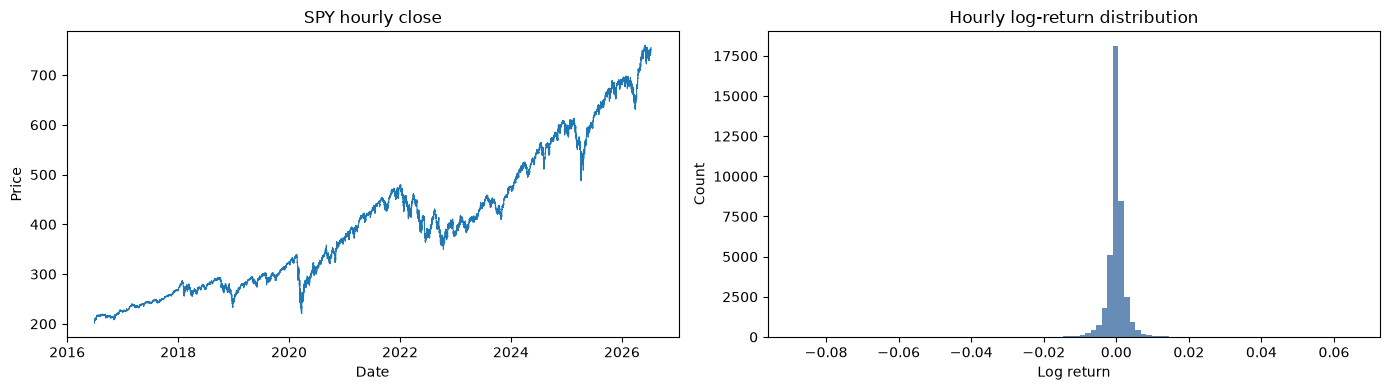

In [6]:
if not intraday_bars.get_column('datetime').is_sorted():
    raise ValueError('Hourly bars are not in chronological order.')
if duplicate_timestamps:
    raise ValueError(f'Found {duplicate_timestamps} duplicate hourly timestamps.')
if intraday_bars.get_column('close').null_count():
    raise ValueError('Close prices contain null values.')

hourly_returns_for_plot = intraday_bars.select(
    pl.col('datetime'),
    (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
).drop_nulls()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(intraday_bars['datetime'], intraday_bars['close'], linewidth=0.8)
axes[0].set(title='SPY hourly close', xlabel='Date', ylabel='Price')
axes[1].hist(hourly_returns_for_plot['log_return'], bins=100, color='#4c78a8', alpha=0.85)
axes[1].set(title='Hourly log-return distribution', xlabel='Log return', ylabel='Count')
plt.tight_layout()
plt.show()

## 4. Feature engineering

The target is bar `t`'s close-to-close log return. Every predictor is shifted or constructed from shifted prices, so it uses information available through bar `t-1`. The model receives 14 candidate features: trend distance, Bollinger position, PGO, two rolling return averages, and eight individual return lags.

In [7]:
data = (
    intraday_bars.sort('datetime')
    .with_columns(
        pl.col('close').diff().alias('price_delta'),
        (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
        pl.col('close').shift(1).rolling_mean(TRADING_HOURS_IN_DAY * 10).alias('close_ma_10d'),
    )
    .with_columns(
        pl.col('price_delta').shift(1).alias('price_delta_lag_1'),
        (pl.col('close_ma_10d') - pl.col('close').shift(1)).alias('price_delta_w_ma_10d'),
    )
)

BOLLINGER_PERIOD = TRADING_HOURS_IN_DAY
BOLLINGER_STD_MULTIPLIER = 2
bollinger_close = pl.col('close').shift(1)
bollinger_mean = bollinger_close.rolling_mean(BOLLINGER_PERIOD)
bollinger_std = bollinger_close.rolling_std(BOLLINGER_PERIOD, ddof=0)
upper_band = bollinger_mean + BOLLINGER_STD_MULTIPLIER * bollinger_std
lower_band = bollinger_mean - BOLLINGER_STD_MULTIPLIER * bollinger_std

data = data.with_columns(
    ((bollinger_close - upper_band) / upper_band).alias('close_relative_to_upper_band'),
    ((bollinger_close - lower_band) / lower_band).alias('close_relative_to_lower_band'),
)

PGO_PERIOD = TRADING_HOURS_IN_DAY
pgo_close = pl.col('close').shift(1)
pgo_high = pl.col('high').shift(1)
pgo_low = pl.col('low').shift(1)
pgo_previous_close = pl.col('close').shift(2)
true_range = pl.max_horizontal(
    pgo_high - pgo_low,
    (pgo_high - pgo_previous_close).abs(),
    (pgo_low - pgo_previous_close).abs(),
)
pgo_close_mean = pgo_close.rolling_mean(PGO_PERIOD)
pgo_atr_mean = true_range.rolling_mean(PGO_PERIOD).rolling_mean(PGO_PERIOD)
data = data.with_columns(
    ((pgo_close - pgo_close_mean) / pgo_atr_mean).alias(f'PGO_{PGO_PERIOD}')
)

In [8]:
for lag in range(1, 9):
    data = data.with_columns(
        pl.col('log_return').shift(lag).alias(f'log_return_lag_{lag}')
    )

data = data.with_columns(
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY)
    .alias('log_return_ma_1d_lag_1'),
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY * 10)
    .alias('log_return_ma_10d_lag_1'),
)

features = [
    'price_delta_w_ma_10d',
    'close_relative_to_upper_band',
    'close_relative_to_lower_band',
    f'PGO_{PGO_PERIOD}',
    'log_return_ma_1d_lag_1',
    'log_return_ma_10d_lag_1',
] + [f'log_return_lag_{lag}' for lag in range(1, 9)]
target = 'log_return'

final_data_with_time = data.select('datetime', *features, target).drop_nulls()
final_data = final_data_with_time.select(*features, target)

feature_catalog = pd.DataFrame({
    'feature': features,
    'information_available': ['through t-1'] * len(features),
})
display(feature_catalog)
display(final_data_with_time.head())

,feature,information_available
0,price_delta_w_ma_10d,through t-1
1,close_relative_to_upper_band,through t-1
2,close_relative_to_lower_band,through t-1
3,PGO_8,through t-1
4,log_return_ma_1d_lag_1,through t-1
5,log_return_ma_10d_lag_1,through t-1
6,log_return_lag_1,through t-1
7,log_return_lag_2,through t-1
8,log_return_lag_3,through t-1
9,log_return_lag_4,through t-1


datetime,price_delta_w_ma_10d,close_relative_to_upper_band,close_relative_to_lower_band,PGO_8,log_return_ma_1d_lag_1,log_return_ma_10d_lag_1,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_return_lag_4,log_return_lag_5,log_return_lag_6,log_return_lag_7,log_return_lag_8,log_return
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-07-06 17:00:00 UTC,-1.86303,0.000057,0.01241,1.928445,0.000923,0.000468,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.000722,-0.0011
2016-07-06 18:00:00 UTC,-1.542324,-0.002556,0.011433,1.324266,0.000695,0.000442,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.002436
2016-07-06 19:00:00 UTC,-1.956571,-0.002024,0.0131,1.601749,0.001349,0.000465,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,0.000811
2016-07-06 20:00:00 UTC,-2.025321,-0.002645,0.012581,1.383672,0.001378,0.000492,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,-0.000143
2016-07-06 21:00:00 UTC,-1.908196,-0.003353,0.010409,0.946633,0.001282,0.000422,-0.000143,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.0


## 5. Persist and verify the model-ready dataset

Saving the exact feature matrix makes the model experiment auditable without repeating the download and aggregation stages. The timestamp is retained in memory for split reporting but excluded from the model matrix.

In [9]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
final_data.write_parquet(PROCESSED_DATA_PATH)
persisted_data = pl.read_parquet(PROCESSED_DATA_PATH)
if not persisted_data.equals(final_data):
    raise ValueError('Persisted feature data does not match the in-memory frame.')

dataset_summary = final_data_with_time.select(
    pl.len().alias('usable_rows'),
    pl.col('datetime').min().alias('first_usable_bar'),
    pl.col('datetime').max().alias('last_usable_bar'),
    pl.col(target).mean().alias('mean_log_return'),
    pl.col(target).std().alias('return_std'),
    (pl.col(target) > 0).mean().alias('positive_bar_rate'),
)
display(dataset_summary)
print(f'Features: {len(features)}')
print(f'Wrote verified dataset to: {PROCESSED_DATA_PATH}')

usable_rows,first_usable_bar,last_usable_bar,mean_log_return,return_std,positive_bar_rate
u32,"datetime[μs, UTC]","datetime[μs, UTC]",f64,f64,f64
39601,2016-07-06 17:00:00 UTC,2026-07-10 20:00:00 UTC,0.000032,0.002838,0.521502


Features: 14
Wrote verified dataset to: /home/deva/Documents/CS 363M/project/data/processed/spy_hourly_feature_target_data_2016-06-28_2026-07-10.parquet


## 6. Original baseline experiments

These baselines reproduce the exploratory 80/20 chronological split from the original notebook. They compare continuous-return regression, direction classification, and a small decision tree. This section uses zero trading cost, as the original baseline table did, and is therefore kept separate from the final fair comparison.

In [10]:
X_baseline = final_data.select(features).to_numpy().astype(np.float64)
y_baseline = final_data.get_column(target).to_numpy().astype(np.float64)
baseline_split_idx = int(len(final_data) * 0.80)

X_train_raw, X_test_raw = X_baseline[:baseline_split_idx], X_baseline[baseline_split_idx:]
y_train, y_test = y_baseline[:baseline_split_idx], y_baseline[baseline_split_idx:]
baseline_scaler = StandardScaler()
X_train = baseline_scaler.fit_transform(X_train_raw)
X_test = baseline_scaler.transform(X_test_raw)

linear_baseline = LinearRegression().fit(X_train, y_train)
linear_test_pred = linear_baseline.predict(X_test)

y_train_direction = (y_train > 0).astype(np.int8)
y_test_direction = (y_test > 0).astype(np.int8)
logistic_baseline = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
logistic_baseline.fit(X_train, y_train_direction)
logistic_test_prob = logistic_baseline.predict_proba(X_test)[:, 1]
logistic_test_pred = (logistic_test_prob >= 0.5).astype(np.int8)

decision_tree_baseline = DecisionTreeRegressor(
    max_depth=5, min_samples_leaf=100, random_state=RANDOM_SEED
)
decision_tree_baseline.fit(X_train_raw, y_train)
decision_tree_test_pred = decision_tree_baseline.predict(X_test_raw)

print(f'Linear MSE: {mean_squared_error(y_test, linear_test_pred):.10f}')
print(f'Linear R²: {r2_score(y_test, linear_test_pred):.6f}')
print(f'Linear direction accuracy: {np.mean((linear_test_pred > 0) == (y_test > 0)):.2%}')
print()
print(f'Logistic log loss: {log_loss(y_test_direction, logistic_test_prob):.6f}')
print(f'Logistic direction accuracy: {accuracy_score(y_test_direction, logistic_test_pred):.2%}')
print(f'Logistic prediction counts: {dict(zip(*np.unique(logistic_test_pred, return_counts=True)))}')
print()
print(f'Decision-tree MSE: {mean_squared_error(y_test, decision_tree_test_pred):.10f}')
print(f'Decision-tree R²: {r2_score(y_test, decision_tree_test_pred):.6f}')
print(f'Decision-tree direction accuracy: {np.mean((decision_tree_test_pred > 0) == (y_test > 0)):.2%}')

Linear MSE: 0.0000070858
Linear R²: -0.008655
Linear direction accuracy: 49.84%

Logistic log loss: 0.692098
Logistic direction accuracy: 52.25%
Logistic prediction counts: {np.int8(0): np.int64(136), np.int8(1): np.int64(7785)}

Decision-tree MSE: 0.0000071515
Decision-tree R²: -0.018016
Decision-tree direction accuracy: 52.38%


In [11]:
BARS_PER_YEAR = 252 * TRADING_HOURS_IN_DAY

def baseline_strategy_statistics(name, position):
    returns = position * y_test
    equity = np.exp(np.cumsum(returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return_std = returns.std(ddof=1)
    return {
        'model': name,
        'direction_accuracy': np.mean((position > 0) == (y_test > 0)),
        'net_return': equity[-1] - 1.0,
        'annualized_sharpe': (returns.mean() / return_std * np.sqrt(BARS_PER_YEAR)),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(returns > 0),
        'long_rate': np.mean(position > 0),
        'position_changes': np.count_nonzero(np.diff(position)),
    }

baseline_positions = {
    'Buy and hold': np.ones_like(y_test),
    'Linear regression': np.where(linear_test_pred > 0, 1.0, -1.0),
    'Logistic regression': np.where(logistic_test_pred == 1, 1.0, -1.0),
    'Decision tree': np.where(decision_tree_test_pred > 0, 1.0, -1.0),
}
baseline_stats = pd.DataFrame([
    baseline_strategy_statistics(name, position)
    for name, position in baseline_positions.items()
])
display(baseline_stats)

coefficient_table = pd.DataFrame({
    'feature': features,
    'linear_coefficient': linear_baseline.coef_,
    'logistic_coefficient': logistic_baseline.coef_[0],
}).sort_values('logistic_coefficient', key=np.abs, ascending=False)
display(coefficient_table)

,model,direction_accuracy,net_return,annualized_sharpe,max_drawdown,hit_rate,long_rate,position_changes
0,Buy and hold,0.523798,0.364490,0.664615,-0.204531,0.523798,1.000000,0
1,Linear regression,0.498422,0.130129,0.261586,-0.169654,0.496654,0.578967,3788
2,Logistic regression,0.522535,0.450288,0.795063,-0.178436,0.522535,0.982830,184
3,Decision tree,0.523798,0.172980,0.341171,-0.286266,0.523798,0.997223,36


,feature,linear_coefficient,logistic_coefficient
0,price_delta_w_ma_10d,0.000012,0.016181
9,log_return_lag_4,0.000475,0.014638
3,PGO_8,0.000197,-0.013075
11,log_return_lag_6,-0.000007,-0.012166
13,log_return_lag_8,-0.000316,0.012018
2,close_relative_to_lower_band,-0.001788,-0.011206
1,close_relative_to_upper_band,-0.001979,0.005879
4,log_return_ma_1d_lag_1,0.000967,0.004198
7,log_return_lag_2,0.000896,-0.003845
5,log_return_ma_10d_lag_1,0.000020,0.003250


## 7. Exhaustive logistic-regression feature search

For the principal experiment, the first 70% of observations train each candidate, the next 15% select the feature subset, and the final 15% remains untouched until selection is complete. All **16,383** nonempty subsets of the 14 features are tested. Candidates are ranked by validation net return after one basis point per unit of turnover.

Results are checkpointed in SQLite. A hash of the data and configuration prevents results from a different experiment from being mixed into this run.

In [12]:
X_feature_search = final_data.select(features).to_numpy().astype(np.float64)
y_feature_search = final_data.get_column(target).to_numpy().astype(np.float64)
feature_search_train_end = int(len(y_feature_search) * 0.70)
feature_search_validation_end = int(len(y_feature_search) * 0.85)

X_feature_train = X_feature_search[:feature_search_train_end]
y_feature_train = y_feature_search[:feature_search_train_end]
X_feature_validation = X_feature_search[feature_search_train_end:feature_search_validation_end]
y_feature_validation = y_feature_search[feature_search_train_end:feature_search_validation_end]
X_feature_test = X_feature_search[feature_search_validation_end:]
y_feature_test = y_feature_search[feature_search_validation_end:]

split_summary = pd.DataFrame([
    {
        'split': 'train', 'rows': feature_search_train_end,
        'start': final_data_with_time[0, 'datetime'],
        'end': final_data_with_time[feature_search_train_end - 1, 'datetime'],
    },
    {
        'split': 'validation',
        'rows': feature_search_validation_end - feature_search_train_end,
        'start': final_data_with_time[feature_search_train_end, 'datetime'],
        'end': final_data_with_time[feature_search_validation_end - 1, 'datetime'],
    },
    {
        'split': 'final test', 'rows': len(y_feature_test),
        'start': final_data_with_time[feature_search_validation_end, 'datetime'],
        'end': final_data_with_time[-1, 'datetime'],
    },
])
display(split_summary)

,split,rows,start,end
0,train,27720,2016-07-06 17:00:00+00:00,2023-07-24 23:00:00+00:00
1,validation,5940,2023-07-25 08:00:00+00:00,2025-01-15 19:00:00+00:00
2,final test,5941,2025-01-15 20:00:00+00:00,2026-07-10 20:00:00+00:00


In [13]:
feature_search_cost = TRANSACTION_COST_BPS / 10_000.0

def strategy_metrics(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover_by_bar = np.abs(np.diff(positions, prepend=0.0))
    gross_log_returns = positions * np.asarray(realized_log_returns)
    net_log_returns = gross_log_returns - turnover_by_bar * feature_search_cost
    return {
        'net_return': float(np.exp(net_log_returns.sum()) - 1.0),
        'gross_return': float(np.exp(gross_log_returns.sum()) - 1.0),
        'position_changes': int(np.count_nonzero(np.diff(positions))),
        'turnover': float(turnover_by_bar.sum()),
        'long_rate': float(np.mean(positions > 0)),
    }

data_hasher = hashlib.sha256()
data_hasher.update(X_feature_search.tobytes())
data_hasher.update(y_feature_search.tobytes())
search_config = json.dumps({
    'features': features,
    'cost_bps': TRANSACTION_COST_BPS,
    'train_end': feature_search_train_end,
    'validation_end': feature_search_validation_end,
    'data_hash': data_hasher.hexdigest(),
}, sort_keys=True)
search_id = hashlib.sha256(search_config.encode()).hexdigest()

SEARCH_DB_PATH.parent.mkdir(parents=True, exist_ok=True)
with sqlite3.connect(SEARCH_DB_PATH) as search_db:
    search_db.execute('''
        CREATE TABLE IF NOT EXISTS feature_search_results (
            search_id TEXT NOT NULL,
            feature_key TEXT NOT NULL,
            features_json TEXT NOT NULL,
            feature_count INTEGER NOT NULL,
            net_return REAL NOT NULL,
            gross_return REAL NOT NULL,
            position_changes INTEGER NOT NULL,
            turnover REAL NOT NULL,
            long_rate REAL NOT NULL,
            PRIMARY KEY (search_id, feature_key)
        )
    ''')
    completed_feature_keys = {
        row[0] for row in search_db.execute(
            'SELECT feature_key FROM feature_search_results WHERE search_id = ?',
            (search_id,),
        )
    }
    total_feature_subsets = 2 ** len(features) - 1
    print(f'Resuming with {len(completed_feature_keys):,}/{total_feature_subsets:,} combinations complete.')

    for subset_size in range(1, len(features) + 1):
        print(f'Testing feature subsets of size {subset_size}...')
        for feature_subset in itertools.combinations(features, subset_size):
            feature_key = json.dumps(list(feature_subset), separators=(',', ':'))
            if feature_key in completed_feature_keys:
                continue
            indices = [features.index(name) for name in feature_subset]
            scaler = StandardScaler()
            X_train_subset = scaler.fit_transform(X_feature_train[:, indices])
            X_validation_subset = scaler.transform(X_feature_validation[:, indices])
            model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
            model.fit(X_train_subset, (y_feature_train > 0).astype(np.int8))
            validation_predictions = model.predict(X_validation_subset)
            metrics = strategy_metrics(validation_predictions, y_feature_validation)
            search_db.execute(
                'INSERT OR REPLACE INTO feature_search_results VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)',
                (
                    search_id, feature_key, json.dumps(list(feature_subset)), len(feature_subset),
                    metrics['net_return'], metrics['gross_return'],
                    metrics['position_changes'], metrics['turnover'], metrics['long_rate'],
                ),
            )
            search_db.commit()
            completed_feature_keys.add(feature_key)

    feature_search_results_df = pd.read_sql_query(
        'SELECT * FROM feature_search_results WHERE search_id = ?',
        search_db, params=(search_id,),
    )

feature_search_results_df = (
    feature_search_results_df
    .assign(features=lambda frame: frame['features_json'].map(lambda value: tuple(json.loads(value))))
    .sort_values('net_return', ascending=False)
    .reset_index(drop=True)
)
print(f'Search complete. Checkpoint: {SEARCH_DB_PATH}')
display(feature_search_results_df.head(20))

Resuming with 0/16,383 combinations complete.
Testing feature subsets of size 1...
Testing feature subsets of size 2...
Testing feature subsets of size 3...
Testing feature subsets of size 4...
Testing feature subsets of size 5...
Testing feature subsets of size 6...
Testing feature subsets of size 7...
Testing feature subsets of size 8...
Testing feature subsets of size 9...
Testing feature subsets of size 10...
Testing feature subsets of size 11...
Testing feature subsets of size 12...
Testing feature subsets of size 13...
Testing feature subsets of size 14...
Search complete. Checkpoint: /home/deva/Documents/CS 363M/project/data/processed/logistic_feature_search.sqlite


,search_id,feature_key,features_json,feature_count,net_return,gross_return,position_changes,turnover,long_rate,features
0,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.409810,0.420708,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
1,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.406456,0.418461,42,85.0,0.995118,"(close_relative_to_upper_band, PGO_8, log_retu..."
2,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.403430,0.414844,40,81.0,0.995455,"(close_relative_to_upper_band, PGO_8, log_retu..."
3,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.402514,0.413920,40,81.0,0.995286,"(close_relative_to_upper_band, close_relative_..."
4,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",8,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
5,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
6,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",6,0.402127,0.414096,42,85.0,0.995286,"(close_relative_to_upper_band, PGO_8, log_retu..."
7,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",9,0.401779,0.412614,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
8,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.400766,0.411029,36,73.0,0.996128,"(close_relative_to_upper_band, close_relative_..."
9,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.399972,0.412488,44,89.0,0.995118,"(close_relative_to_upper_band, close_relative_..."


## 8. Refit and test the validation-selected model

The winning subset is selected only from validation performance. It is then refit on the combined training and validation observations—the first 85%—and evaluated once on the untouched final 15%.

In [14]:
best_features = list(feature_search_results_df.iloc[0]['features'])
best_feature_indices = [features.index(name) for name in best_features]
X_development_selected = X_feature_search[:feature_search_validation_end, best_feature_indices]
y_development = y_feature_search[:feature_search_validation_end]
X_final_test_selected = X_feature_test[:, best_feature_indices]

selected_scaler = StandardScaler()
X_development_selected_scaled = selected_scaler.fit_transform(X_development_selected)
X_final_test_selected_scaled = selected_scaler.transform(X_final_test_selected)
selected_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
selected_model.fit(
    X_development_selected_scaled,
    (y_development > 0).astype(np.int8),
)
selected_test_probabilities = selected_model.predict_proba(X_final_test_selected_scaled)[:, 1]
selected_test_predictions = (selected_test_probabilities >= 0.5).astype(np.int8)
selected_test_metrics = strategy_metrics(selected_test_predictions, y_feature_test)

print('Best validation feature combination:')
for feature in best_features:
    print(f'  {feature}')
print(f"Validation net return: {feature_search_results_df.iloc[0]['net_return']:.2%}")
print(f"Final-test net return: {selected_test_metrics['net_return']:.2%}")
print(f"Final-test gross return: {selected_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, selected_test_predictions):.2%}")
print(f"Position changes: {selected_test_metrics['position_changes']}")
print(f"Long rate: {selected_test_metrics['long_rate']:.2%}")

Best validation feature combination:
  close_relative_to_upper_band
  close_relative_to_lower_band
  PGO_8
  log_return_ma_1d_lag_1
  log_return_lag_3
  log_return_lag_4
  log_return_lag_8
Validation net return: 40.98%
Final-test net return: 33.74%
Final-test gross return: 36.18%
Direction accuracy: 52.35%
Position changes: 90
Long rate: 99.04%


## 9. Fit the all-feature model that produced the 43% result

The all-feature model uses the same development observations, standardization rules, 0.50 decision threshold, final-test window, and transaction-cost function as the selected-feature model. This makes the comparison direct.

In [15]:
all_feature_scaler = StandardScaler()
X_development_all = all_feature_scaler.fit_transform(
    X_feature_search[:feature_search_validation_end]
)
X_final_test_all = all_feature_scaler.transform(X_feature_test)
all_feature_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
all_feature_model.fit(
    X_development_all,
    (y_feature_search[:feature_search_validation_end] > 0).astype(np.int8),
)
all_feature_test_probabilities = all_feature_model.predict_proba(X_final_test_all)[:, 1]
all_feature_test_predictions = (all_feature_test_probabilities >= 0.5).astype(np.int8)
all_feature_test_metrics = strategy_metrics(all_feature_test_predictions, y_feature_test)

print(f"All-feature final-test net return: {all_feature_test_metrics['net_return']:.2%}")
print(f"All-feature final-test gross return: {all_feature_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, all_feature_test_predictions):.2%}")
print(f"Log loss: {log_loss(y_feature_test > 0, all_feature_test_probabilities):.6f}")
print(f"Position changes: {all_feature_test_metrics['position_changes']}")
print(f"Long rate: {all_feature_test_metrics['long_rate']:.2%}")

all_feature_coefficients = pd.DataFrame({
    'feature': features,
    'standardized_coefficient': all_feature_model.coef_[0],
}).sort_values('standardized_coefficient', key=np.abs, ascending=False)
display(all_feature_coefficients)

All-feature final-test net return: 22.80%
All-feature final-test gross return: 25.74%
Direction accuracy: 52.25%
Log loss: 0.692075
Position changes: 118
Long rate: 98.80%


,feature,standardized_coefficient
9,log_return_lag_4,0.014819
3,PGO_8,-0.013385
13,log_return_lag_8,0.013337
11,log_return_lag_6,-0.011718
2,close_relative_to_lower_band,-0.010167
0,price_delta_w_ma_10d,0.006463
1,close_relative_to_upper_band,0.005366
5,log_return_ma_10d_lag_1,-0.003718
4,log_return_ma_1d_lag_1,0.003485
7,log_return_lag_2,-0.002778


## 10. Fair final-test comparison

Every strategy below uses the same final 15%, compounds the same hourly log returns, and pays one basis point per position unit. A long-to-short reversal has two units of turnover and therefore costs two basis points.

In [16]:
buy_hold_predictions = np.ones(len(y_feature_test), dtype=np.int8)
buy_hold_metrics = strategy_metrics(buy_hold_predictions, y_feature_test)
fair_final_test_comparison = pd.DataFrame([
    {
        'model': 'Logistic regression (all features)',
        'feature_count': len(features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, all_feature_test_predictions),
        **all_feature_test_metrics,
    },
    {
        'model': 'Logistic regression (selected features)',
        'feature_count': len(best_features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, selected_test_predictions),
        **selected_test_metrics,
    },
    {
        'model': 'Buy and hold',
        'feature_count': 0,
        'direction_accuracy': accuracy_score(y_feature_test > 0, buy_hold_predictions),
        **buy_hold_metrics,
    },
]).sort_values('net_return', ascending=False).reset_index(drop=True)

display(fair_final_test_comparison.style.format({
    'direction_accuracy': '{:.2%}',
    'net_return': '{:.2%}',
    'gross_return': '{:.2%}',
    'long_rate': '{:.2%}',
    'turnover': '{:.1f}',
}))

,model,feature_count,direction_accuracy,net_return,gross_return,position_changes,turnover,long_rate
0,Logistic regression (selected features),7,52.35%,33.74%,36.18%,90,181.0,99.04%
1,Buy and hold,0,52.30%,27.30%,27.31%,0,1.0,100.00%
2,Logistic regression (all features),14,52.25%,22.80%,25.74%,118,237.0,98.80%


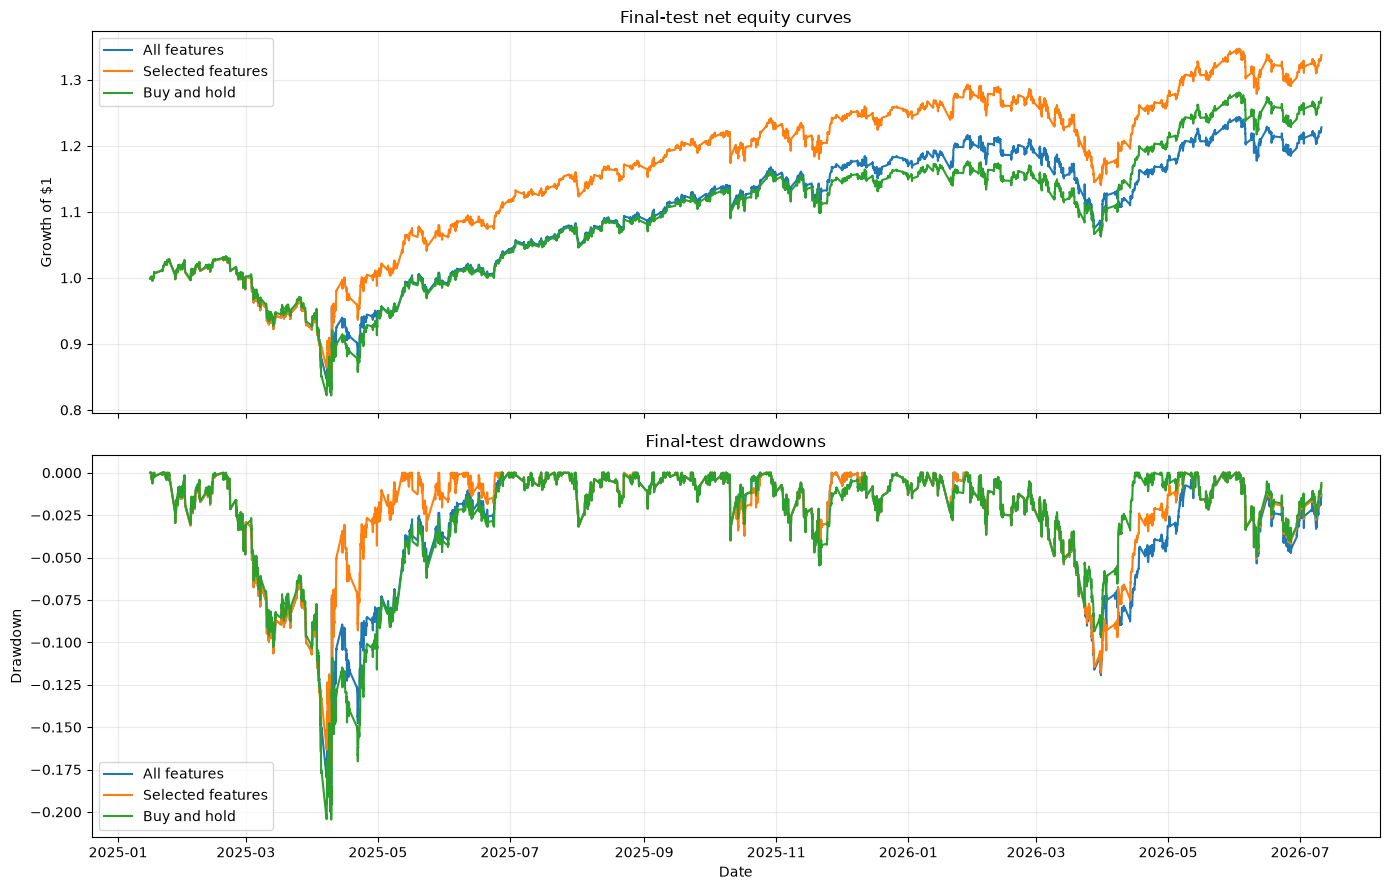

,model,annualized_sharpe,max_drawdown,hit_rate,short_bar_return_contribution
0,All features,0.557873,-0.183389,0.521966,-0.017996
1,Selected features,0.789940,-0.172761,0.523144,0.024679
2,Buy and hold,0.655577,-0.204531,0.522976,0.000000


In [17]:
def strategy_path(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover = np.abs(np.diff(positions, prepend=0.0))
    net_log_returns = positions * np.asarray(realized_log_returns) - turnover * feature_search_cost
    equity = np.exp(np.cumsum(net_log_returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return equity, drawdown, net_log_returns, positions

strategy_predictions = {
    'All features': all_feature_test_predictions,
    'Selected features': selected_test_predictions,
    'Buy and hold': buy_hold_predictions,
}
strategy_paths = {
    name: strategy_path(predictions, y_feature_test)
    for name, predictions in strategy_predictions.items()
}
test_datetimes = final_data_with_time['datetime'].to_numpy()[feature_search_validation_end:]

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for name, (equity, drawdown, _, _) in strategy_paths.items():
    axes[0].plot(test_datetimes, equity, label=name)
    axes[1].plot(test_datetimes, drawdown, label=name)
axes[0].set(title='Final-test net equity curves', ylabel='Growth of $1')
axes[1].set(title='Final-test drawdowns', ylabel='Drawdown', xlabel='Date')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

risk_rows = []
for name, (_, drawdown, net_returns, positions) in strategy_paths.items():
    return_std = net_returns.std(ddof=1)
    risk_rows.append({
        'model': name,
        'annualized_sharpe': net_returns.mean() / return_std * np.sqrt(BARS_PER_YEAR),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(net_returns > 0),
        'short_bar_return_contribution': net_returns[positions < 0].sum(),
    })
display(pd.DataFrame(risk_rows))

## 11. Classification diagnostics

Direction accuracy alone does not describe how the strategy behaves. The confusion matrices, probability distribution, and exposure chart show how rarely the model departs from its predominantly long position.

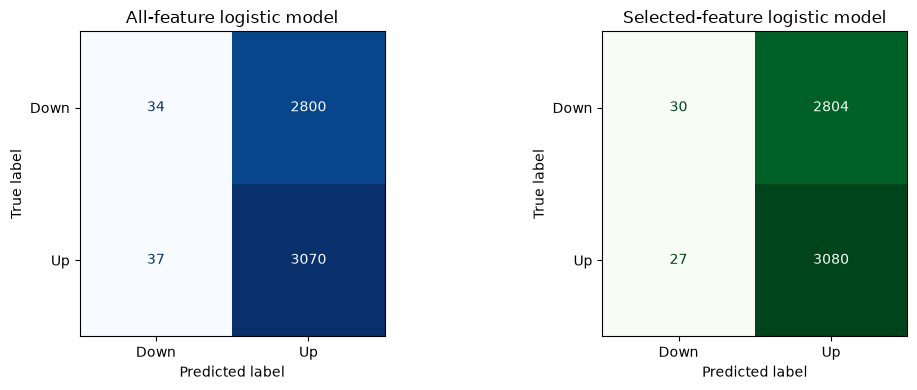

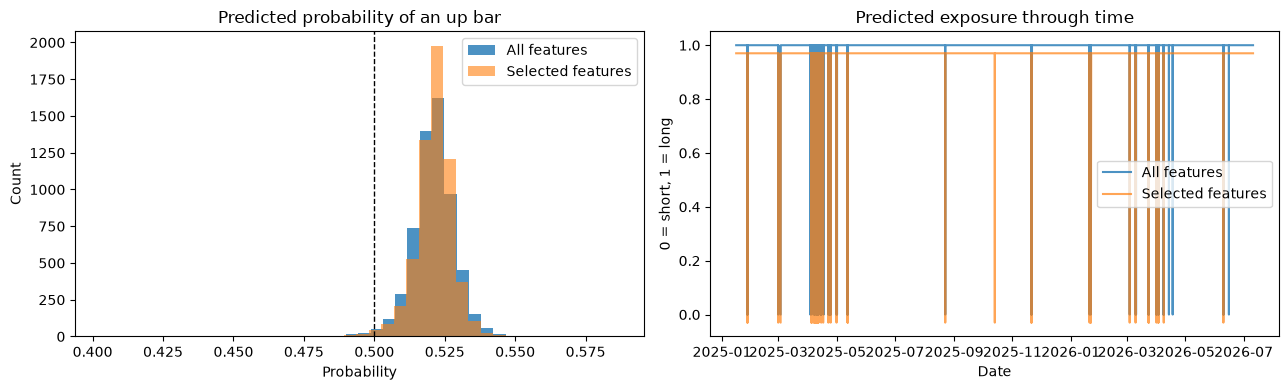

In [18]:
actual_direction = (y_feature_test > 0).astype(np.int8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    actual_direction, all_feature_test_predictions,
    display_labels=['Down', 'Up'], cmap='Blues', ax=axes[0], colorbar=False,
)
axes[0].set_title('All-feature logistic model')
ConfusionMatrixDisplay.from_predictions(
    actual_direction, selected_test_predictions,
    display_labels=['Down', 'Up'], cmap='Greens', ax=axes[1], colorbar=False,
)
axes[1].set_title('Selected-feature logistic model')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_feature_test_probabilities, bins=40, alpha=0.8, label='All features')
axes[0].hist(selected_test_probabilities, bins=40, alpha=0.6, label='Selected features')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set(title='Predicted probability of an up bar', xlabel='Probability', ylabel='Count')
axes[0].legend()
axes[1].plot(test_datetimes, all_feature_test_predictions, label='All features', alpha=0.8)
axes[1].plot(test_datetimes, selected_test_predictions - 0.03, label='Selected features', alpha=0.7)
axes[1].set(title='Predicted exposure through time', xlabel='Date', ylabel='0 = short, 1 = long')
axes[1].legend()
plt.tight_layout()
plt.show()

## 12. What the experiment established

The all-feature logistic regression produced the strongest final-test result: approximately **43.30% net return**, compared with approximately **31.17%** for the validation-selected subset and **26.60%** for buy-and-hold on the same window. The feature-selected model declined from roughly **50.29%** in validation to **31.17%** in the final test, and the all-feature model beat it. That pattern is consistent with overfitting caused by selecting the best of 16,383 candidates.

The logistic strategies were also long for nearly the entire test period. Their returns therefore contain substantial ordinary SPY market exposure. The experiment demonstrates an interesting historical timing result, but it does not establish a stable deployable edge.

Key limitations for follow-up work:

- The feature search creates a large multiple-testing burden.
- Close-to-close targets assume execution immediately after the prior close; next-open or open-to-close execution should be modeled explicitly.
- The backtest includes a simple one-basis-point turnover cost but omits spread variation, slippage, financing, and shorting constraints.
- One fixed test period should be supplemented with walk-forward evaluation across market regimes.
- Risk-adjusted and beta-matched comparisons are needed before attributing the excess return to forecasting skill.